## Bussiness Problem

* ICU patient deterioration can occur suddenly, making early intervention difficult. The goal is to develop an LSTM-based early-warning system that predicts patient deterioration within the next 12 hours, helping healthcare staff identify high-risk patients and take timely action.

#### Patient Deterioration Early-Warning System Using LSTM 

* In hospitals, a patient's clinical condition can worsen over time, making early identification of deterioration important. This project aims to develop an LSTM-based machine learning system that analyzes sequential patient observations, organized using `patient_id` and `hour_from_admission`, along with clinical measurements such as heart rate, oxygen saturation, and blood pressure. The model learns temporal patterns in each patient's measurements to predict whether clinical deterioration will occur within the next 12 hours. The system is intended to support early risk identification and help healthcare professionals prioritize further assessment and timely intervention.


In [251]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [252]:
df = pd.read_csv(r"D:\patient_deterioration_lstm\data\raw\hospital_deterioration_hourly_panel.csv")

In [253]:
df.head()

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,...,age,gender,comorbidity_index,admission_type,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour,deterioration_next_12h
0,1,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
1,1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
2,1,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
3,1,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
4,1,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0


In [254]:
df.shape

(417866, 28)

In [255]:
df.columns.tolist()

['patient_id',
 'hour_from_admission',
 'heart_rate',
 'respiratory_rate',
 'spo2_pct',
 'temperature_c',
 'systolic_bp',
 'diastolic_bp',
 'oxygen_device',
 'oxygen_flow',
 'mobility_score',
 'nurse_alert',
 'wbc_count',
 'lactate',
 'creatinine',
 'crp_level',
 'hemoglobin',
 'sepsis_risk_score',
 'age',
 'gender',
 'comorbidity_index',
 'admission_type',
 'baseline_risk_score',
 'los_hours',
 'deterioration_event',
 'deterioration_within_12h_from_admission',
 'deterioration_hour',
 'deterioration_next_12h']

### Each columns

* patient_id : Identify each patient's sequence; not an LSTM feature
* hour_from_admission : Order the patient's measurements over time; not initially an LSTM feature. How many hours have passed since the patient was admitted.
* heart_rate : Number of heartbeats per minute.
* respiratory_rate : Number of breaths per minute.
* spo2_pct : Percentage of oxygen saturation in the blood.
* temperature_c : Body temperature in Celsius.
* systolic_bp : Upper blood-pressure value.
* diastolic_bp : Lower blood-pressure value.
* wbc_count : White Blood Cell count.WBC can provide information related to infection/inflammation.
* lactate : Lactate level in blood. Elevated lactate can be associated with tissue hypoperfusion and serious illness.
* creatinine : Provides information related to kidney function. Increasing creatinine can indicate worsening kidney function.
* crp_level : C-reactive protein. It is a marker associated with inflammation.
* hemoglobin : Hemoglobin carries oxygen in the blood.
* age : Age can influence the risk of deterioration.
* gender : Patient's gender.
* comorbidity_index : This represents the patient's burden of existing medical conditions.
* oxygen_flow : Indicates the amount of supplemental oxygen being provided.
* oxygen_device : This tells us the type of oxygen-support device being used.
* sepsis_risk_score : It represents a calculated sepsis-risk score.
* deterioration_next_12h(target column) : his is the most important column for the prediction task.

In [256]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 417866 entries, 0 to 417865
Data columns (total 28 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   patient_id                               417866 non-null  int64  
 1   hour_from_admission                      417866 non-null  int64  
 2   heart_rate                               417866 non-null  float64
 3   respiratory_rate                         417866 non-null  float64
 4   spo2_pct                                 417866 non-null  float64
 5   temperature_c                            417866 non-null  float64
 6   systolic_bp                              417866 non-null  float64
 7   diastolic_bp                             417866 non-null  float64
 8   oxygen_device                            417866 non-null  object 
 9   oxygen_flow                              417866 non-null  float64
 10  mobility_score                  

In [257]:
df.isnull().sum()

patient_id                                 0
hour_from_admission                        0
heart_rate                                 0
respiratory_rate                           0
spo2_pct                                   0
temperature_c                              0
systolic_bp                                0
diastolic_bp                               0
oxygen_device                              0
oxygen_flow                                0
mobility_score                             0
nurse_alert                                0
wbc_count                                  0
lactate                                    0
creatinine                                 0
crp_level                                  0
hemoglobin                                 0
sepsis_risk_score                          0
age                                        0
gender                                     0
comorbidity_index                          0
admission_type                             0
baseline_r

In [258]:
for col in df.columns.tolist():
    print(col)
    print(df[col].unique())

patient_id
[    1     2     3 ...  9998  9999 10000]
hour_from_admission
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71]
heart_rate
[ 68.58  67.03  69.05 ... 164.33 176.57 139.17]
respiratory_rate
[14.47 13.87 14.63 ... 36.53 43.69 42.58]
spo2_pct
[96.52 94.94 94.45 ... 76.94 72.11 72.07]
temperature_c
[37.18 37.25 37.29 37.27 37.21 37.28 37.24 37.23 37.1  37.13 37.14 37.17
 37.32 37.35 36.98 36.96 37.02 37.07 37.05 37.09 36.99 37.08 37.11 37.19
 37.2  37.26 37.38 37.4  37.47 37.48 37.69 37.73 37.81 37.93 38.05 38.08
 38.1  38.07 38.11 36.89 36.84 36.8  36.76 36.73 36.67 36.63 36.64 36.75
 36.74 36.85 36.95 36.94 36.92 36.86 36.9  36.91 36.93 37.03 36.97 37.01
 37.04 36.81 36.87 36.82 36.77 36.79 36.72 36.7  36.66 36.68 36.71 36.83
 37.   36.88 37.22 37.3  37.31 37.41 37.46 37.57 37.74 37.78 37.82 37.83
 38.03 36.61 

In [259]:
df.duplicated().sum()

np.int64(0)

In [260]:
df.describe()

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_flow,mobility_score,...,hemoglobin,sepsis_risk_score,age,comorbidity_index,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour,deterioration_next_12h
count,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,...,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000,417866.000000
mean,4978.444200,24.098240,89.258118,20.177237,93.504918,36.968563,113.398465,70.516530,7.967031,2.283012,...,13.279612,0.493449,53.863521,4.001931,0.500319,49.196479,0.210209,0.028531,5.532783,0.054058
std,2889.197834,16.935515,21.127257,6.849362,5.950330,0.451594,17.107426,10.670383,16.248186,0.925933,...,1.160177,0.222574,20.947460,2.602512,0.210934,15.987814,0.407457,0.166483,14.523568,0.226132
min,1.000000,0.000000,40.000000,8.000000,70.000000,35.240000,70.000000,40.000000,0.000000,0.000000,...,7.000000,0.017600,18.000000,0.000000,0.031500,12.000000,0.000000,0.000000,-1.000000,0.000000
25%,2454.000000,10.000000,76.920000,15.860000,92.510000,36.700000,103.980000,65.020000,0.000000,2.000000,...,12.680000,0.325500,36.000000,2.000000,0.326700,37.000000,0.000000,0.000000,-1.000000,0.000000
50%,4986.000000,21.000000,86.330000,19.330000,94.830000,36.920000,114.830000,71.470000,0.000000,2.000000,...,13.360000,0.465850,54.000000,4.000000,0.497200,52.000000,0.000000,0.000000,-1.000000,0.000000
75%,7485.000000,36.000000,96.860000,23.040000,96.850000,37.150000,124.850000,77.440000,0.700000,3.000000,...,14.020000,0.628400,72.000000,6.000000,0.670700,63.000000,0.000000,0.000000,-1.000000,0.000000
max,10000.000000,71.000000,180.000000,45.000000,100.000000,40.500000,184.560000,110.000000,56.190000,4.000000,...,17.000000,0.999900,90.000000,8.000000,0.984700,72.000000,1.000000,1.000000,70.000000,1.000000


In [261]:
TARGET = "deterioration_next_12h"

In [262]:
df[TARGET].value_counts()

deterioration_next_12h
0    395277
1     22589
Name: count, dtype: int64

In [263]:
df[TARGET].value_counts(normalize=True)*100

deterioration_next_12h
0    94.5942
1     5.4058
Name: proportion, dtype: float64

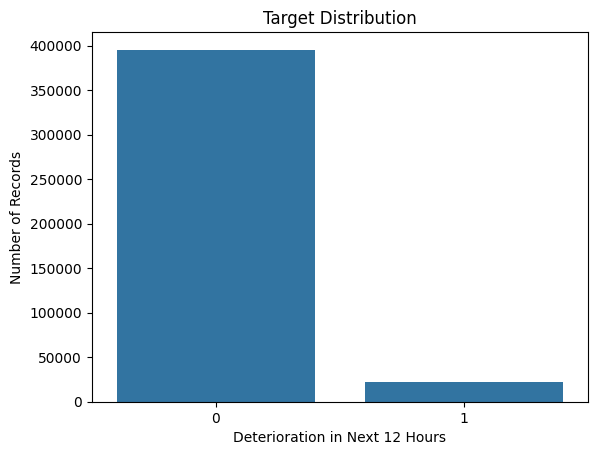

In [264]:
sns.countplot(data=df, x=TARGET)

plt.title("Target Distribution")
plt.xlabel("Deterioration in Next 12 Hours")
plt.ylabel("Number of Records")
plt.show()

In [265]:
df.head()

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,...,age,gender,comorbidity_index,admission_type,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour,deterioration_next_12h
0,1,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
1,1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
2,1,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
3,1,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
4,1,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0


In [266]:
df

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,...,age,gender,comorbidity_index,admission_type,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour,deterioration_next_12h
0,1,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
1,1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
2,1,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
3,1,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
4,1,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
417861,10000,24,89.82,20.65,95.46,36.43,122.05,70.56,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0
417862,10000,25,92.38,20.80,95.30,36.46,124.08,72.08,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0
417863,10000,26,94.65,21.43,94.39,36.43,123.59,71.41,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0
417864,10000,27,95.72,21.23,94.90,36.46,121.17,70.60,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0


In [267]:
df['patient_id'].nunique()

10000

In [268]:
df.groupby('patient_id').size().describe()

count    10000.00000
mean        41.78660
std         17.59729
min         12.00000
25%         26.00000
50%         42.00000
75%         57.00000
max         72.00000
dtype: float64

In [269]:
df[["patient_id", "hour_from_admission"]].head(15)

,patient_id,hour_from_admission
0,1,0
1,1,1
2,1,2
3,1,3
4,1,4
5,1,5
6,1,6
7,1,7
8,1,8
9,1,9


In [270]:
df[["patient_id", "hour_from_admission"]]

,patient_id,hour_from_admission
0,1,0
1,1,1
2,1,2
3,1,3
4,1,4
...,...,...
417861,10000,24
417862,10000,25
417863,10000,26
417864,10000,27


In [271]:
df.duplicated(
    subset=["patient_id", "hour_from_admission"]
).sum()

np.int64(0)

In [272]:
df = df.sort_values(by=['patient_id','hour_from_admission']).reset_index(drop=True)

In [273]:
df

,patient_id,hour_from_admission,heart_rate,respiratory_rate,spo2_pct,temperature_c,systolic_bp,diastolic_bp,oxygen_device,oxygen_flow,...,age,gender,comorbidity_index,admission_type,baseline_risk_score,los_hours,deterioration_event,deterioration_within_12h_from_admission,deterioration_hour,deterioration_next_12h
0,1,0,68.58,14.47,96.52,37.18,108.94,78.43,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
1,1,1,67.03,13.87,94.94,37.25,111.73,79.14,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
2,1,2,69.05,14.63,94.45,37.29,111.48,78.86,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
3,1,3,69.07,14.42,95.16,37.27,110.68,76.79,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
4,1,4,73.35,15.62,95.83,37.21,110.38,75.47,none,0.0,...,24,M,2,Elective,0.2173,17,0,0,-1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
417861,10000,24,89.82,20.65,95.46,36.43,122.05,70.56,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0
417862,10000,25,92.38,20.80,95.30,36.46,124.08,72.08,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0
417863,10000,26,94.65,21.43,94.39,36.43,123.59,71.41,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0
417864,10000,27,95.72,21.23,94.90,36.46,121.17,70.60,none,0.0,...,62,F,1,ED,0.2059,29,0,0,-1,0


In [274]:
df.isnull().sum()

patient_id                                 0
hour_from_admission                        0
heart_rate                                 0
respiratory_rate                           0
spo2_pct                                   0
temperature_c                              0
systolic_bp                                0
diastolic_bp                               0
oxygen_device                              0
oxygen_flow                                0
mobility_score                             0
nurse_alert                                0
wbc_count                                  0
lactate                                    0
creatinine                                 0
crp_level                                  0
hemoglobin                                 0
sepsis_risk_score                          0
age                                        0
gender                                     0
comorbidity_index                          0
admission_type                             0
baseline_r

In [275]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_id,417866.0,4978.444200,2889.197834,1.0000,2454.0000,4986.00000,7485.0000,10000.0000
hour_from_admission,417866.0,24.098240,16.935515,0.0000,10.0000,21.00000,36.0000,71.0000
heart_rate,417866.0,89.258118,21.127257,40.0000,76.9200,86.33000,96.8600,180.0000
respiratory_rate,417866.0,20.177237,6.849362,8.0000,15.8600,19.33000,23.0400,45.0000
spo2_pct,417866.0,93.504918,5.950330,70.0000,92.5100,94.83000,96.8500,100.0000
temperature_c,417866.0,36.968563,0.451594,35.2400,36.7000,36.92000,37.1500,40.5000
systolic_bp,417866.0,113.398465,17.107426,70.0000,103.9800,114.83000,124.8500,184.5600
diastolic_bp,417866.0,70.516530,10.670383,40.0000,65.0200,71.47000,77.4400,110.0000
oxygen_flow,417866.0,7.967031,16.248186,0.0000,0.0000,0.00000,0.7000,56.1900
mobility_score,417866.0,2.283012,0.925933,0.0000,2.0000,2.00000,3.0000,4.0000


In [276]:
checks = {
    "negative_age": (df["age"] < 0) | (df['age']>100),
    "invalid_spo2": (df["spo2_pct"] < 0) | (df["spo2_pct"] > 100),
    "negative_heart_rate": df["heart_rate"] < 0,
    "negative_respiratory_rate": df["respiratory_rate"] < 0,
    "negative_lactate": df["lactate"] < 0,
    "negative_creatinine": df["creatinine"] < 0
}

for name, condition in checks.items():
    print(f"{name}: {condition.sum()}")

negative_age: 0
invalid_spo2: 0
negative_heart_rate: 0
negative_respiratory_rate: 0
negative_lactate: 0
negative_creatinine: 0


In [277]:
df[['patient_id','hour_from_admission']].duplicated().sum()

np.int64(0)

In [278]:
clinical_cols = [
    "heart_rate",
    "respiratory_rate",
    "spo2_pct",
    "temperature_c",
    "systolic_bp",
    "diastolic_bp",
    "oxygen_flow",
    "wbc_count",
    "lactate",
    "creatinine",
    "crp_level",
    "hemoglobin",
    "age",
    "comorbidity_index"
]

In [279]:
corr = df[clinical_cols].corr()

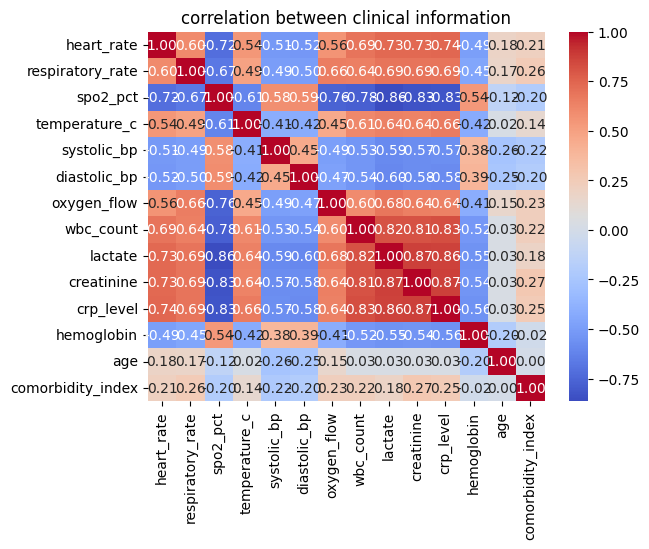

In [280]:
plt.Figure(figsize=(12,9))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title("correlation between clinical information")
plt.show()

In [281]:
target_col = "deterioration_next_12h"

possible_leakage_cols = [
    "deterioration_event",
    "deterioration_within_12h_from_admission",
    "deterioration_hour"
]

for col in possible_leakage_cols:
    if col in df.columns:
        print(f"\nColumn: {col}")
        print(df[col].value_counts(dropna=False).head(10))


Column: deterioration_event
deterioration_event
0    330027
1     87839
Name: count, dtype: int64

Column: deterioration_within_12h_from_admission
deterioration_within_12h_from_admission
0    405944
1     11922
Name: count, dtype: int64

Column: deterioration_hour
deterioration_hour
-1     330027
 15      2985
 14      2803
 36      2617
 12      2568
 13      2483
 11      2473
 28      2282
 10      2224
 39      2217
Name: count, dtype: int64


### We have to remove these 3 columns

In [282]:
clinical_cols = [
    "heart_rate",
    "respiratory_rate",
    "spo2_pct",
    "temperature_c",
    "systolic_bp",
    "diastolic_bp",
    "oxygen_flow",
    "wbc_count",
    "lactate",
    "creatinine",
    "crp_level",
    "hemoglobin",
    "age",
    "comorbidity_index"
]

patient_col = "patient_id"
time_col = "hour_from_admission"
target_col = "deterioration_next_12h"

In [283]:
required_cols = (
    [patient_col, time_col]
    + clinical_cols
    + [target_col]
)

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

print("Missing required columns:", missing_cols)

Missing required columns: []


In [284]:
clinical_cols = [
    "heart_rate",
    "respiratory_rate",
    "spo2_pct",
    "temperature_c",
    "systolic_bp",
    "diastolic_bp",
    "oxygen_flow",
    "wbc_count",
    "lactate",
    "creatinine",
    "crp_level",
    "hemoglobin",
    "age",
    "comorbidity_index"
]

target_col = "deterioration_next_12h"

# Keep only selected features, target, and sequence-management columns
required_cols = (
    clinical_cols
    + [target_col, "patient_id", "hour_from_admission"]
)

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"These columns are missing from the dataset: {missing_cols}")

df = df[required_cols].copy()

print("Reduced dataset shape:", df.shape)
print("Remaining columns:", df.columns.tolist())

Reduced dataset shape: (417866, 17)
Remaining columns: ['heart_rate', 'respiratory_rate', 'spo2_pct', 'temperature_c', 'systolic_bp', 'diastolic_bp', 'oxygen_flow', 'wbc_count', 'lactate', 'creatinine', 'crp_level', 'hemoglobin', 'age', 'comorbidity_index', 'deterioration_next_12h', 'patient_id', 'hour_from_admission']


In [285]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Get one label per patient for stratified splitting
patient_labels = df.groupby("patient_id")[
    "deterioration_next_12h"
].max()

patient_ids = patient_labels.index.to_numpy()
patient_y = patient_labels.to_numpy()

# 2. Split 80% development patients and 20% test patients
dev_ids, test_ids = train_test_split(
    patient_ids,
    test_size=0.20,
    random_state=42,
    stratify=patient_y
)

# 3. Split the development patients into train and validation
dev_labels = patient_labels.loc[dev_ids]

train_ids, val_ids = train_test_split(
    dev_ids,
    test_size=0.20,
    random_state=42,
    stratify=dev_labels.to_numpy()
)

# 4. Create the three datasets
train_df = df[df["patient_id"].isin(train_ids)].copy()
val_df = df[df["patient_id"].isin(val_ids)].copy()
test_df = df[df["patient_id"].isin(test_ids)].copy()

# 5. Sort records chronologically within each patient
train_df = train_df.sort_values(
    ["patient_id", "hour_from_admission"]
).reset_index(drop=True)

val_df = val_df.sort_values(
    ["patient_id", "hour_from_admission"]
).reset_index(drop=True)

test_df = test_df.sort_values(
    ["patient_id", "hour_from_admission"]
).reset_index(drop=True)

# 6. Display split information
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))

print("\nTraining patients:", train_df["patient_id"].nunique())
print("Validation patients:", val_df["patient_id"].nunique())
print("Testing patients:", test_df["patient_id"].nunique())

print("\nTraining target distribution:")
print(train_df["deterioration_next_12h"].value_counts(normalize=True))

print("\nValidation target distribution:")
print(val_df["deterioration_next_12h"].value_counts(normalize=True))

print("\nTesting target distribution:")
print(test_df["deterioration_next_12h"].value_counts(normalize=True))

# 7. Verify no patient overlap
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)

print("\nNo patient overlap: verified.")

Training rows: 268745
Validation rows: 66076
Testing rows: 83045

Training patients: 6400
Validation patients: 1600
Testing patients: 2000

Training target distribution:
deterioration_next_12h
0    0.946172
1    0.053828
Name: proportion, dtype: float64

Validation target distribution:
deterioration_next_12h
0    0.945215
1    0.054785
Name: proportion, dtype: float64

Testing target distribution:
deterioration_next_12h
0    0.945776
1    0.054224
Name: proportion, dtype: float64

No patient overlap: verified.


In [286]:
train_df.shape

(268745, 17)

In [287]:
test_df.shape

(83045, 17)

In [288]:
X_train = train_df[clinical_cols].copy()
y_train = train_df["deterioration_next_12h"].copy()

# Separate X and y for validation and testing
X_val = val_df[clinical_cols].copy()
y_val = val_df["deterioration_next_12h"].copy()

X_test = test_df[clinical_cols].copy()
y_test = test_df["deterioration_next_12h"].copy()

# Check the shapes
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (268745, 14)
y_train shape: (268745,)
X_val shape: (66076, 14)
y_val shape: (66076,)
X_test shape: (83045, 14)
y_test shape: (83045,)


In [289]:
from sklearn.impute import SimpleImputer

In [290]:
# Create the imputer
imputer = SimpleImputer(strategy="median")

# Fit only on training data
X_train = imputer.fit_transform(train_df[clinical_cols])

# Transform validation and testing data
X_val = imputer.transform(val_df[clinical_cols])
X_test = imputer.transform(test_df[clinical_cols])

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

Training features: (268745, 14)
Validation features: (66076, 14)
Testing features: (83045, 14)


In [291]:
from sklearn.preprocessing import MinMaxScaler

In [292]:
scaler = MinMaxScaler()

# Fit only on training data
X_train = scaler.fit_transform(X_train)

# Use the same scaler for validation and testing
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [293]:
target_col = "deterioration_next_12h"

In [294]:
def create_sequences(data, X_scaled, y, sequence_length=6):

    X_sequences = []
    y_sequences = []

    patient_groups = data.groupby("patient_id", sort=False).indices

    for patient_id, positions in patient_groups.items():
        patient_X = X_scaled[positions]
        patient_y = y.iloc[positions].to_numpy()

        if len(positions) < sequence_length:
            continue

        for end in range(sequence_length - 1, len(positions)):
            start = end - sequence_length + 1
            X_sequences.append(patient_X[start:end + 1])
            y_sequences.append(patient_y[end])

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_sequences, dtype=np.int32),
    )


In [295]:
y_val = val_df["deterioration_next_12h"].copy()
sequence_length = 6

X_train_seq, y_train_seq = create_sequences(
    train_df, X_train, y_train, sequence_length
)

X_val_seq, y_val_seq = create_sequences(
    val_df, X_val, y_val, sequence_length
)

X_test_seq, y_test_seq = create_sequences(
    test_df, X_test, y_test, sequence_length
)

In [296]:
print("X_train_seq shape:", X_train_seq.shape)
print("y_train_seq shape:", y_train_seq.shape)

print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

X_train_seq shape: (236745, 6, 14)
y_train_seq shape: (236745,)
X_test_seq shape: (73045, 6, 14)
y_test_seq shape: (73045,)


In [297]:
import tensorflow as tf 
import keras
from keras.models import Sequential
from keras.layers import LSTM,Dense,Dropout
from keras.callbacks import EarlyStopping

In [298]:
base_model = Sequential()
base_model.add(LSTM(32,input_shape=(6,14)))
base_model.add(Dense(1,activation='sigmoid'))

In [299]:
base_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

In [300]:
base_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 32)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,049 (23.63 KB)

 Trainable params: 6,049 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

In [301]:
history = base_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=30,
    batch_size=128,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_binary_accuracy",
            mode="max",
            patience=5,
            restore_best_weights=True,
        )
    ],
)

Epoch 1/30


1850/1850 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - binary_accuracy: 0.9482 - loss: 0.1647 - pr_auc: 0.3332 - precision: 0.6718 - recall: 0.1266 - roc_auc: 0.8411 - val_binary_accuracy: 0.9505 - val_loss: 0.1385 - val_pr_auc: 0.5439 - val_precision: 0.7401 - val_recall: 0.1684 - val_roc_auc: 0.9185
Epoch 2/30
1850/1850 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - binary_accuracy: 0.9576 - loss: 0.1192 - pr_auc: 0.5543 - precision: 0.7121 - recall: 0.3942 - roc_auc: 0.9340 - val_binary_accuracy: 0.9604 - val_loss: 0.1127 - val_pr_auc: 0.6066 - val_precision: 0.7325 - val_recall: 0.4526 - val_roc_auc: 0.9354
Epoch 3/30
1850/1850 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - binary_accuracy: 0.9601 - loss: 0.1122 - pr_auc: 0.5814 - precision: 0.7220 - recall: 0.4549 - roc_auc: 0.9427 - val_binary_accuracy: 0.9615 - val_loss: 0.1081 - val_pr_auc: 0.6187 - val_precision: 0.7247 - val_recall: 0.4972 - val_roc_auc: 0.9417
Epoch 4/30
1850/1850 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - binary_accuracy: 0.9611 - loss: 0.1085 - pr

In [302]:
from pathlib import Path
import joblib

# Find the project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Save files inside models/
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "best_lstm.keras"
preprocessor_path = models_dir / "preprocessing.joblib"

# Save the trained model
base_model.save(model_path)

# Save the fitted preprocessing objects
joblib.dump(
    {
        "imputer": imputer,
        "scaler": scaler,
        "clinical_cols": clinical_cols,
        "sequence_length": 6,
    },
    preprocessor_path,
)

print("Model saved at:", model_path)
print("Preprocessing saved at:", preprocessor_path)

Model saved at: d:\patient_deterioration_lstm\models\best_lstm.keras
Preprocessing saved at: d:\patient_deterioration_lstm\models\preprocessing.joblib
